# 04. Resultados dos cenários

**Como a avaliação funciona.** Em cada sexta-feira do planejamento, o algoritmo aprende só com dias anteriores e prevê a semana-alvo, como aconteceria na prática.

- **2024 e 2025** serviram para escolher o comitê do artefato: média de CatBoost, KNN e consumo de referência, com os últimos 12 meses. A escolha foi fixada antes de medir 2026.
- **2026 (fevereiro a outubro)** é a prova: nada foi ajustado depois de ver o resultado.
- Os resultados aparecem **com e sem os dias atípicos**.
- O intervalo de 95% mostra a incerteza. **Se ele inclui o zero, a diferença pode ser apenas acaso.**

Os dados de 2026 já haviam sido examinados em etapas anteriores do projeto, então esta prova é retrospectiva. Os termos estão no `GLOSSARIO.md`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("../src")
from nomes import ALTERNATIVAS, CENARIOS, HISTORICOS, JANELAS, MODELOS, UNIVERSOS, rotulo

pd.set_option("display.max_rows", 90, "display.max_columns", 30, "display.width", 180, "display.max_colwidth", 60)
RESULTADOS = Path("..") / "resultados" / "modelos"
FIGURAS = Path("..") / "resultados" / "figuras"

SUPERFICIE, TEXTO2, GRADE = "#fcfcfb", "#52514e", "#e6e5e0"
AZUL, LARANJA, AQUA, VIOLETA, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#9b9a93"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE, "axes.edgecolor": GRADE,
    "axes.labelcolor": TEXTO2, "xtick.color": TEXTO2, "ytick.color": TEXTO2, "axes.grid": True, "grid.color": GRADE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True, "font.size": 10,
})

def ler(nome):
    return pd.read_csv(RESULTADOS / f"{nome}.csv", sep=";", encoding="utf-8-sig")

resultado, escolhas, janelas, metricas = ler("resultado_final"), ler("configuracao_escolhida"), ler("comparacao_janelas_treino"), ler("metricas_janelas_treino")
preparo = pd.read_parquet(RESULTADOS / "preparo_diario_final.parquet")
compras = pd.read_parquet(RESULTADOS / "compras_diario_final.parquet")

def intervalo(linha):
    return "" if pd.isna(linha["ic_inf"]) else f"{linha['ic_inf']:.1f} a {linha['ic_sup']:.1f}"

def tabela(janela, periodo, universo, nome_ref):
    d = resultado[(resultado["janela"] == janela) & (resultado["periodo"] == periodo) & (resultado["universo"] == universo)].copy()
    d["Intervalo de 95%"] = d.apply(intervalo, axis=1)
    d["alternativa"] = d["alternativa"].map(ALTERNATIVAS)
    colunas = {"alternativa": "Alternativa", "mae": rotulo("mae"), "vies": rotulo("vies"), "excesso": rotulo("excesso"), "deficit": rotulo("deficit"),
               "dias_deficit": "% de dias com déficit potencial", "dif_referencia": f"Diferença para {nome_ref}", "Intervalo de 95%": "Intervalo de 95%"}
    return d[list(colunas)].rename(columns=colunas).round(1).reset_index(drop=True)

## 1. Quanto histórico usar para aprender

Cada linha é o comitê campeão com um histórico diferente. Menor erro médio é melhor.

In [2]:
base = metricas[(metricas["universo"] == "sem_atipicos")].merge(escolhas[["janela", "cenario", "modelo"]], on=["janela", "cenario", "modelo"])
tab = base.pivot_table(index=["janela", "cenario"], columns=["periodo", "janela_treino"], values="mae").round(1)
tab = tab.rename(columns=HISTORICOS, level=1).rename(columns={"escolha_2025": "Escolha em 2025", "prova_2026": "Prova em 2026"}, level=0)
tab.rename(index=JANELAS, level=0).rename(index=CENARIOS, level=1).rename_axis(index=["Decisão", "Cenário"], columns=["Período", "Histórico"])

Período                                                               Escolha em 2025                                                                                              \
Histórico                                                            Últimos 12 meses Últimos 2 anos Últimos 6 meses Ano anterior + ano atual até agora Todo o histórico anterior   
Decisão                        Cenário                                                                                                                                              
Preparo (semana seguinte)      Cenário 1: consumo e calendário                   19.7           19.8            20.4                               19.9                      19.7   
                               Cenário 2: inclui o cardápio                      19.7           19.6            20.3                               20.0                      19.6   
                               Cenário 3: inclui a previsão do tempo             19.8           19.8            20.4                               19.8                      19.8   
                               H                                                 20.8           20.9            20.9                               20.9                      21.0   
Compras (daqui a duas semanas) Cenário 1: consumo e calendário                   20.4           19.9            21.3                               19.9                      19.8   
                               Cenário 2: inclui o cardápio                      20.3           19.8            21.2                               19.7                      19.6   
                               H                                                 20.8           20.4            21.3                               20.3                      20.3   

Período                                                                 Prova em 2026                                                                                              
Histórico                                                            Últimos 12 meses Últimos 2 anos Últimos 6 meses Ano anterior + ano atual até agora Todo o histórico anterior  
Decisão                        Cenário                                                                                                                                             
Preparo (semana seguinte)      Cenário 1: consumo e calendário                   25.6           26.3            26.4                               25.8                      25.5  
                               Cenário 2: inclui o cardápio                      25.6           26.3            26.6                               25.8                      25.6  
                               Cenário 3: inclui a previsão do tempo             25.1           26.1            26.0                               26.1                      26.1  
                               H                                                 27.4           27.5            28.5                               27.6                      26.9  
Compras (daqui a duas semanas) Cenário 1: consumo e calendário                   25.3           26.6            28.1                               25.4                      25.1  
                               Cenário 2: inclui o cardápio                      25.6           26.3            27.9                               25.9                      24.6  
                               H                                                 28.1           28.8            30.0                               28.0                      27.6

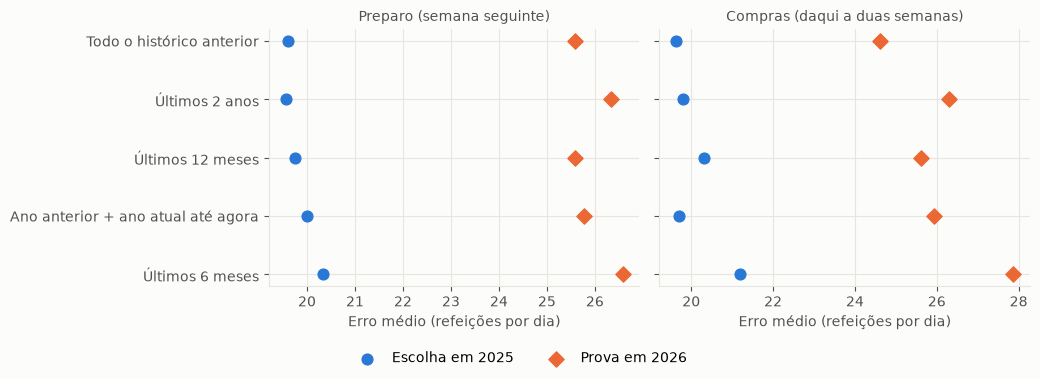

,Decisão,Cenário,Últimos 12 meses contra,Diferença (refeições por dia),Intervalo de 95%
0,Preparo (semana seguinte),Cenário 1: consumo e calendário,Últimos 2 anos,-0.7,-1.6 a 0.1
1,Preparo (semana seguinte),Cenário 1: consumo e calendário,Últimos 6 meses,-0.9,-2.8 a 0.9
2,Preparo (semana seguinte),Cenário 1: consumo e calendário,Ano anterior + ano atual até agora,-0.2,-1.0 a 0.5
3,Preparo (semana seguinte),Cenário 1: consumo e calendário,Todo o histórico anterior,0.1,-1.3 a 1.8
4,Preparo (semana seguinte),Cenário 2: inclui o cardápio,Últimos 2 anos,-0.8,-1.8 a 0.2
5,Preparo (semana seguinte),Cenário 2: inclui o cardápio,Últimos 6 meses,-1.0,-3.1 a 0.9
6,Preparo (semana seguinte),Cenário 2: inclui o cardápio,Ano anterior + ano atual até agora,-0.2,-0.9 a 0.5
7,Preparo (semana seguinte),Cenário 2: inclui o cardápio,Todo o histórico anterior,-0.0,-1.3 a 1.5
8,Preparo (semana seguinte),Cenário 3: inclui a previsão do tempo,Últimos 2 anos,-1.1,-2.0 a -0.2
9,Preparo (semana seguinte),Cenário 3: inclui a previsão do tempo,Últimos 6 meses,-0.9,-3.2 a 1.0


In [3]:
ordem = ["tudo", "2_anos", "1_ano", "ano_anterior_e_atual", "6_meses"]
fig, eixos = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, (janela, cenario) in zip(eixos, [("t1", "C2"), ("t2", "C2")]):
    d = base[(base["janela"] == janela) & (base["cenario"] == cenario)].set_index("janela_treino")
    p25 = d[d["periodo"] == "escolha_2025"]["mae"].reindex(ordem)
    p26 = d[d["periodo"] == "prova_2026"]["mae"].reindex(ordem)
    y = range(len(ordem))
    ax.scatter(p25, y, s=60, color=AZUL, label="Escolha em 2025", zorder=3)
    ax.scatter(p26, y, s=60, color=LARANJA, marker="D", label="Prova em 2026", zorder=3)
    ax.set_yticks(list(y), [HISTORICOS[o] for o in ordem])
    ax.invert_yaxis() if ax is eixos[0] else None
    ax.set_title(JANELAS[janela], fontsize=10, color=TEXTO2)
    ax.set_xlabel("Erro médio (refeições por dia)")
fig.legend(*eixos[0].get_legend_handles_labels(), frameon=False, loc="lower center", ncol=2)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(FIGURAS / "06_historico_de_treino.png", dpi=200)
plt.show()

c = janelas.assign(Decisão=janelas["janela"].map(JANELAS), Cenário=janelas["cenario"].map(CENARIOS), Comparado_com=janelas["comparada"].map(HISTORICOS))
c["Diferença (refeições por dia)"] = c["dif"].round(1)
c["Intervalo de 95%"] = c.apply(intervalo, axis=1)
c[["Decisão", "Cenário", "Comparado_com", "Diferença (refeições por dia)", "Intervalo de 95%"]].rename(columns={"Comparado_com": "Últimos 12 meses contra"})

## 2. Comitê campeão em cada cenário

In [4]:
e = escolhas.assign(Decisão=escolhas["janela"].map(JANELAS), Cenário=escolhas["cenario"].map(CENARIOS), Modelo=escolhas["modelo"].map(MODELOS),
                    Histórico=escolhas["janela_treino"].map(HISTORICOS), Erro_em_2025=escolhas["mae"].round(1))
e[["Decisão", "Cenário", "Modelo", "Histórico", "Erro_em_2025"]].rename(columns={"Erro_em_2025": "Erro médio em 2025"})

,Decisão,Cenário,Modelo,Histórico,Erro médio em 2025
0,Preparo (semana seguinte),Cenário 1: consumo e calendário,"Comitê de CatBoost, KNN e consumo de referência",Últimos 12 meses,19.7
1,Preparo (semana seguinte),Cenário 2: inclui o cardápio,"Comitê de CatBoost, KNN e consumo de referência",Últimos 12 meses,19.7
2,Preparo (semana seguinte),Cenário 3: inclui a previsão do tempo,"Comitê de CatBoost, KNN e consumo de referência",Últimos 12 meses,19.8
3,Preparo (semana seguinte),NaN,"Comitê de CatBoost, KNN e consumo de referência",Últimos 12 meses,20.8
4,Compras (daqui a duas semanas),Cenário 1: consumo e calendário,"Comitê de CatBoost, KNN e consumo de referência",Últimos 12 meses,20.4
5,Compras (daqui a duas semanas),Cenário 2: inclui o cardápio,"Comitê de CatBoost, KNN e consumo de referência",Últimos 12 meses,20.3
6,Compras (daqui a duas semanas),NaN,"Comitê de CatBoost, KNN e consumo de referência",Últimos 12 meses,20.8


## 3. Preparo: prova em 2026

Comparação com o quantitativo da nutricionista, nas mesmas datas. O quantitativo chega na sexta-feira à tarde, com a mesma antecedência da previsão.

In [5]:
for universo in ("sem_atipicos", "todos_os_dias"):
    print(UNIVERSOS[universo])
    display(tabela("t1", "prova_2026", universo, "a nutricionista"))

Sem dias atípicos


,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para a nutricionista,Intervalo de 95%
0,Quantitativo da nutricionista,23.7,10.4,2544.0,994.0,39.6,NaN,
1,Consumo de referência,28.0,1.0,2157.0,2014.0,55.7,4.2,-2.6 a 11.8
2,Só histórico de consumo,27.4,0.7,2092.0,1994.0,56.4,3.7,-3.0 a 10.7
3,Cenário 1: consumo e calendário,25.6,1.4,2008.0,1806.0,55.7,1.9,-4.3 a 8.3
4,Cenário 2: inclui o cardápio,25.6,0.3,1929.0,1882.0,58.4,1.8,-4.4 a 8.2
5,Cenário 3: inclui a previsão do tempo,25.1,0.4,1899.0,1835.0,58.4,1.3,-4.7 a 7.4
6,Cenário 4: inclui o quantitativo da nutricionista,20.9,8.1,2159.0,952.0,42.3,-2.9,-6.3 a 0.9


Todos os dias


,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para a nutricionista,Intervalo de 95%
0,Quantitativo da nutricionista,29.0,16.3,3533.0,994.0,37.8,NaN,
1,Consumo de referência,32.8,7.0,3100.0,2014.0,53.2,3.8,-3.1 a 10.9
2,Só histórico de consumo,32.2,6.6,3024.0,1994.0,53.8,3.1,-3.1 a 10.0
3,Cenário 1: consumo e calendário,30.5,7.4,2959.0,1806.0,53.2,1.5,-4.4 a 7.9
4,Cenário 2: inclui o cardápio,30.5,6.4,2879.0,1882.0,55.8,1.5,-4.6 a 7.8
5,Cenário 3: inclui a previsão do tempo,30.2,6.7,2875.0,1835.0,55.8,1.2,-4.7 a 7.2
6,Cenário 4: inclui o quantitativo da nutricionista,26.3,14.1,3158.0,952.0,40.4,-2.7,-6.1 a 1.0


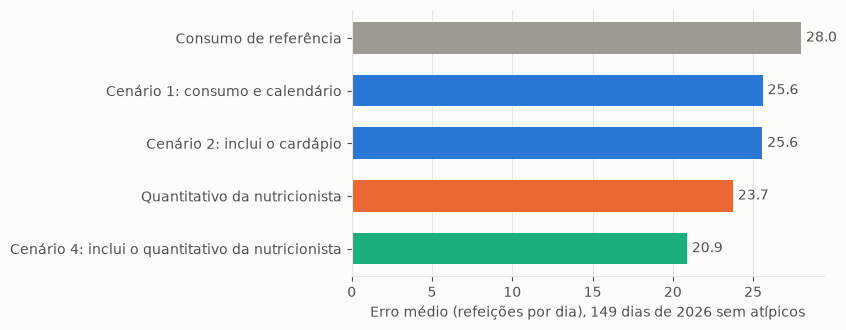

In [6]:
d = resultado[(resultado["janela"] == "t1") & (resultado["periodo"] == "prova_2026") & (resultado["universo"] == "sem_atipicos")].set_index("alternativa")
ordem = ["consumo_tipico", "C1", "C2", "plano", "C4"]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
cores = [CINZA, AZUL, AZUL, LARANJA, AQUA]
ax.barh([ALTERNATIVAS[o] for o in ordem], d.loc[ordem, "mae"], height=0.6, color=cores)
for y, o in enumerate(ordem):
    ax.text(d.loc[o, "mae"] + 0.3, y, f"{d.loc[o, 'mae']:.1f}", va="center", color=TEXTO2)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Erro médio (refeições por dia), 149 dias de 2026 sem atípicos")
fig.tight_layout()
fig.savefig(FIGURAS / "07_preparo_prova_2026.png", dpi=200)
plt.show()

### Mês a mês

O resultado não é uniforme: o artefato e a nutricionista erram em momentos diferentes, e é isso que dá valor ao híbrido.

In [7]:
p = preparo[(preparo["periodo"] == "prova_2026") & preparo["consumo"].notna()].copy()
p["Mês"] = p["data"].dt.strftime("%Y-%m")
mensal = p.groupby("Mês").apply(lambda g: pd.Series({
    "Dias": len(g), "Nutricionista": (g["plano"] - g["consumo"]).abs().mean(), "Artefato (cenário 2)": (g["C2"] - g["consumo"]).abs().mean(),
    "Híbrido (cenário 4)": (g["C4"] - g["consumo"]).abs().mean()}), include_groups=False).round(1)
mensal

,Dias,Nutricionista,Artefato (cenário 2),Híbrido (cenário 4)
Mês,,,,
2026-02,14.0,25.4,32.7,20.9
2026-03,22.0,23.6,32.9,18.9
2026-04,19.0,16.3,17.8,12.8
2026-05,18.0,31.9,22.2,23.6
2026-06,20.0,32.8,25.7,23.4
2026-07,9.0,33.2,81.9,67.3
2026-08,21.0,24.2,25.6,23.0
2026-09,16.0,50.2,46.5,50.2
2026-10,17.0,29.4,18.2,21.9


## 4. Compras: prova em 2026

Não existe quantitativo com duas semanas de antecedência, então a referência é o consumo de referência.

In [8]:
for universo in ("sem_atipicos", "todos_os_dias"):
    print(UNIVERSOS[universo])
    display(tabela("t2", "prova_2026", universo, "o consumo de referência"))

Sem dias atípicos


,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para o consumo de referência,Intervalo de 95%
0,Consumo de referência,28.3,-0.8,2050.0,2169.0,61.1,NaN,
1,Só histórico de consumo,28.1,-1.8,1955.0,2228.0,60.4,-0.2,-2.1 a 1.7
2,Cenário 1: consumo e calendário,25.3,-1.4,1781.0,1987.0,61.1,-3.0,-5.8 a -0.6
3,Cenário 2: inclui o cardápio,25.6,-2.5,1723.0,2095.0,62.4,-2.7,-5.3 a -0.3


Todos os dias


,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para o consumo de referência,Intervalo de 95%
0,Consumo de referência,32.9,5.1,2965.0,2169.0,58.3,NaN,
1,Só histórico de consumo,32.6,4.0,2856.0,2228.0,57.7,-0.3,-2.2 a 1.5
2,Cenário 1: consumo e calendário,30.2,4.7,2727.0,1987.0,58.3,-2.7,-5.3 a -0.3
3,Cenário 2: inclui o cardápio,30.4,3.5,2647.0,2095.0,59.6,-2.5,-5.0 a -0.1


## 5. O algoritmo contra o consumo de referência, no preparo

In [9]:
tabela("t1_vs_tipico", "prova_2026", "sem_atipicos", "o consumo de referência")

,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para o consumo de referência,Intervalo de 95%
0,Consumo de referência,28.0,1.0,2157.0,2014.0,55.7,NaN,
1,Só histórico de consumo,27.4,0.7,2092.0,1994.0,56.4,-0.6,-2.1 a 1.1
2,Cenário 1: consumo e calendário,25.6,1.4,2008.0,1806.0,55.7,-2.4,-4.7 a -0.2
3,Cenário 2: inclui o cardápio,25.6,0.3,1929.0,1882.0,58.4,-2.4,-4.7 a -0.5
4,Cenário 3: inclui a previsão do tempo,25.1,0.4,1899.0,1835.0,58.4,-2.9,-5.4 a -0.8


## 6. Limites desta avaliação

- Os excessos e déficits são diferenças entre plano e consumo registrado. Não medem descarte nem pessoas sem refeição.
- A prova cobre um ano só e um único restaurante.
- 2026 já tinha sido observado nas etapas exploratórias do projeto; a confirmação independente depende de previsões guardadas antes do serviço.
- O cenário 3 ficou fora do comitê porque não reduziu o erro em 2025, e a previsão do tempo segue disponível como alerta.
- A configuração anterior foi melhor em 2026, mas não voltou: trocar agora usaria a prova para escolher. Os detalhes estão no `REVISAO.md`.
- O cenário 4 usa os pesos aprendidos em cada ano; em fevereiro de 2026 ainda não há histórico do quantitativo, e o peso começa em 50%.